# Predicción del crimen - Modelo para predecir la ubicación del próximo crimen

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Data exploratory (Explorar datos)

In [2]:
cluster = pd.read_csv("cluster_location-co.csv")

crime = pd.read_csv('crime-colombia.csv', header=0)
print(crime.head())

         City  crimeCluster  Murder  Assault  CaseResolved  Kidnapping
0      Bogota             4    13.2      236            58        21.2
1    Medellin             4    10.0      263            48        44.5
2  El Encanto             4     8.1      294            80        31.0
3     Caceres             3     8.8      190            50        19.5
4     Cordoba             4     9.0      276            91        40.6


In [3]:
def stateToNumber(s):
    l = 0
    for x in s:
        l = l + int(hex(ord(x)),16)
    return l

xref = pd.DataFrame(crime['City'])
crime['City']=crime['City'].apply(lambda x: stateToNumber(x))
crime.head()

,City,crimeCluster,Murder,Assault,CaseResolved,Kidnapping
0,604,4,13.2,236,58,21.2
1,810,4,10.0,263,48,44.5
2,921,4,8.1,294,80,31.0
3,694,3,8.8,190,50,19.5
4,698,4,9.0,276,91,40.6


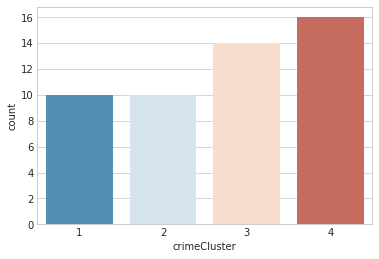

In [4]:
%matplotlib inline

sns.set_style('whitegrid')
sns.countplot(x='crimeCluster',data=crime,palette='RdBu_r')

## 2. Model Training (Entrenamiento modelo)

In [5]:
from sagemaker import KMeans
from sagemaker import get_execution_role

role = get_execution_role()
print(role)

bucket = "alexbc.datalake"

data_location = 's3://{}/kidnapping-records/model/data'.format(bucket)
output_location = 's3://{}/kidnapping-records/model/output'.format(bucket)

print('training data will be uploaded to: {}'.format(data_location))
print('training artifacts will be uploaded to: {}'.format(output_location))

kmeans = KMeans(role=role,
                train_instance_count=1,
                train_instance_type='ml.m5.xlarge',
                output_path=output_location,
                k=10,
                data_location=data_location)

arn:aws:iam::771620814942:role/service-role/AmazonSageMaker-ExecutionRole-20171212T090635
training data will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/data
training artifacts will be uploaded to: s3://alexbc.datalake/kidnapping-records/model/output


In [6]:
crimeArray = crime.as_matrix().astype(np.float32)
crimeArray.shape
slice=crimeArray[:,1:5]

In [ ]:
%%time
kmeans.fit(kmeans.record_set(slice))

INFO:sagemaker:Creating training-job with name: kmeans-2019-02-27-16-08-36-376


2019-02-27 16:08:36 Starting - Starting the training job...
2019-02-27 16:08:38 Starting - Launching requested ML instances...

## 3. Model Deployment - (Mover el modelo a la producción).

In [ ]:
%%time
kmeans_predictor = kmeans.deploy(initial_instance_count=1,
                                 instance_type='ml.t2.large')

# 99. Other examples

https://aws.amazon.com/blogs/publicsector/estimating-hurricane-wind-speeds-with-machine-learning/